# Import All Frameworks


In [5]:
import pandas as pd
import numpy as np

## Load Dataset

In [6]:
df = pd.read_csv("/Users/theerdhasjoy/BIA/ML/Dataset/Housing.csv")
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [7]:
print("Shape :", df.shape)

Shape : (545, 13)


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 69.2 KB


In [9]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [10]:
df.describe(include="O")

/var/folders/y5/lf_stmcj5nv2hnzy3q1b5pb80000gn/T/ipykernel_89021/504318277.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="O")


,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


## Missing values

In [11]:
df.isna().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

## Target Variable

In [12]:
target = "price"

## Categorical vs Numerical

In [13]:
cat_cols = df.select_dtypes(include = "object").columns.tolist()
num_cols = df.select_dtypes(include = np.number).columns.drop(target).tolist()

print("Categorical :", cat_cols)
print("Numerical :", num_cols)

Categorical : ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
Numerical : ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']


/var/folders/y5/lf_stmcj5nv2hnzy3q1b5pb80000gn/T/ipykernel_89021/1315447722.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include = "object").columns.tolist()


In [14]:
df["prefarea"].nunique()

2

In [15]:
df["furnishingstatus"].value_counts()

furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64

In [16]:
df["furnishingstatus"].nunique()

3

# Feature Engineering

In [17]:
for cols in num_cols:
    df[cols] = df[cols].fillna(df[cols].mean())
for col in cat_cols:
    df[cols] = df[cols].fillna(df[cols].mode()[0])

print("Missing after imputation:", df.isna().sum())

print("Avg of Missing after imputation:", df.isna().sum().sum())

Missing after imputation: price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64
Avg of Missing after imputation: 0


# Encoding categorical variables

In [18]:
pip install scikit-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [19]:
df["furnishingstatus"]

0           furnished
1           furnished
2      semi-furnished
3           furnished
4           furnished
            ...      
540       unfurnished
541    semi-furnished
542       unfurnished
543         furnished
544       unfurnished
Name: furnishingstatus, Length: 545, dtype: str

In [20]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

le.fit_transform(df["furnishingstatus"])

array([0, 0, 1, 0, 0, 1, 1, 2, 0, 2, 0, 1, 1, 0, 1, 1, 2, 0, 0, 1, 1, 2,
       0, 0, 0, 0, 1, 1, 2, 1, 2, 1, 0, 2, 0, 0, 0, 0, 2, 1, 0, 0, 2, 1,
       0, 1, 0, 0, 2, 1, 2, 2, 0, 1, 1, 2, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0,
       0, 2, 0, 0, 1, 2, 2, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 2, 1,
       2, 0, 1, 0, 0, 1, 1, 1, 0, 1, 2, 2, 2, 2, 1, 0, 0, 2, 1, 2, 1, 1,
       1, 2, 0, 0, 0, 1, 2, 0, 0, 1, 0, 1, 1, 0, 0, 1, 2, 2, 0, 1, 2, 1,
       1, 2, 1, 2, 2, 1, 1, 0, 2, 1, 1, 2, 0, 0, 1, 1, 1, 1, 2, 1, 0, 1,
       1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 2, 2, 1, 0, 1, 1, 1, 2, 2, 2, 1,
       0, 1, 1, 1, 1, 0, 1, 1, 0, 2, 0, 1, 2, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 0, 1, 1, 2, 2, 1, 0, 1, 2,
       1, 1, 1, 0, 2, 1, 1, 0, 1, 1, 1, 1, 0, 2, 1, 1, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 2, 1, 2, 1, 0, 1, 1, 1, 0, 1, 2, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 1, 2, 1, 1, 2, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 2, 0, 2, 0, 0, 1,
       0, 2, 2, 1, 1, 2, 1, 2, 1, 1, 1, 2, 1, 0, 1,

In [21]:
pd.get_dummies(
    df,
    columns = ["furnishingstatus"],
    dtype = int
              
)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,1,0,0
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,1,0,0
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,0,1,0
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,1,0,0
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,0,0,1
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,0,1,0
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,0,0,1
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,1,0,0


## Custom Approach

In [22]:
df = pd.read_csv("/Users/theerdhasjoy/BIA/ML/Dataset/Housing.csv")

print(df[["mainroad", "guestroom", "basement",
          "hotwaterheating", "airconditioning",
          "prefarea", "furnishingstatus"]].head())

print(df["mainroad"].unique())
print(df["furnishingstatus"].unique())

  mainroad guestroom basement hotwaterheating airconditioning prefarea  \
0      yes        no       no              no             yes      yes   
1      yes        no       no              no             yes       no   
2      yes        no      yes              no              no      yes   
3      yes        no      yes              no             yes      yes   
4      yes       yes      yes              no             yes       no   

  furnishingstatus  
0        furnished  
1        furnished  
2   semi-furnished  
3        furnished  
4        furnished  
<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
<ArrowStringArray>
['furnished', 'semi-furnished', 'unfurnished']
Length: 3, dtype: str


In [23]:
yes_no_cols = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]

for cols in yes_no_cols:
    df[cols] = df[cols].map(
                       {
                           "yes" : 1,
                           "no" : 0
                       })
df["furnishingstatus"] = df["furnishingstatus"].map({
    "unfurnished" : 0,
    "semi-furnished" : 1,
    "furnished" : 2
})

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,2
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,2
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,2
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,2


## Visualization

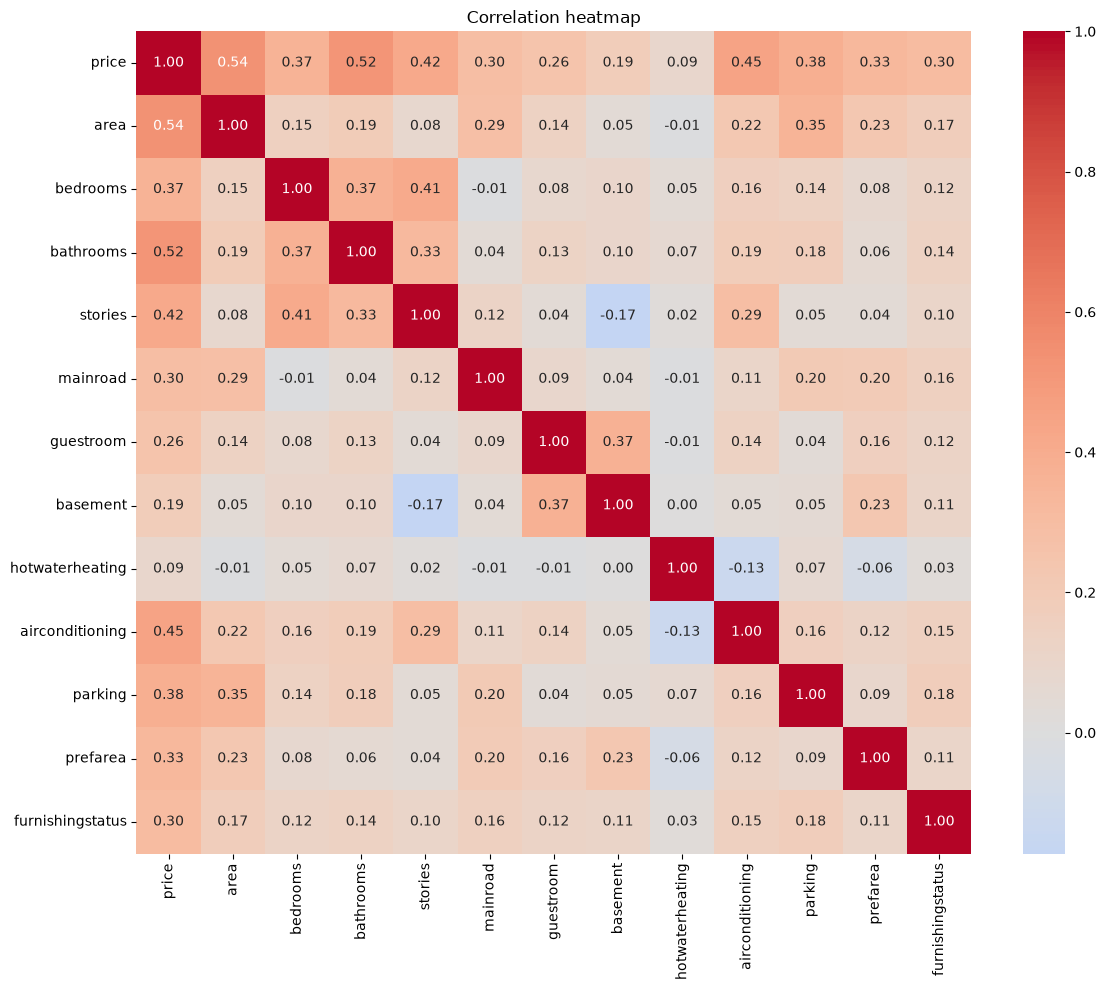

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize =(12,10))
sns.heatmap(df.corr(),annot=True, fmt = ".2f", cmap ="coolwarm", center = 0)
plt.title("Correlation heatmap"); plt.tight_layout(); plt.show()


## Train - Test Split

In [25]:
target = "price"

In [26]:
from sklearn.model_selection import train_test_split

#  x = df.drop("price", axis = 1)

x = df.drop(columns= target) 
y = df[target]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size= 0.2, random_state= 42
)

print(x_test)




     area  bedrooms  bathrooms  stories  mainroad  guestroom  basement  \
316  5900         4          2        2         0          0         1   
77   6500         3          2        3         1          0         0   
360  4040         2          1        1         1          0         0   
90   5000         3          1        2         1          0         0   
493  3960         3          1        1         1          0         0   
..    ...       ...        ...      ...       ...        ...       ...   
15   6000         4          1        2         1          0         1   
357  6930         4          1        2         0          0         0   
39   6000         4          2        4         1          0         0   
54   6000         3          2        2         1          1         0   
155  6100         3          2        1         1          0         1   

     hotwaterheating  airconditioning  parking  prefarea  furnishingstatus  
316                0              

In [27]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='str')

In [28]:
df[col].dtype

dtype('int64')

## Function to find the num_cols, cat_cols, its length and the target

In [29]:
def column_info(df, target):
    
    num_cols = df.select_dtypes(include= np.number).columns.tolist()
    cat_cols = df.select_dtypes(include= "object").columns.tolist()

    if target in num_cols:
        num_cols.remove(target)
    elif target in cat_cols:
        cat_cols.remove(target)

    num_count = len(num_cols)
    cat_count = len(cat_cols)

    return num_cols, cat_cols, num_count, cat_count

# num_cols, cat_cols, num_count, cat_count = column_info(df, "price")

# print(f"The numerical columns are : {num_cols}")
# print(f"The categorical columns are : {cat_cols}")
# print(f"The no.of numerical columns are : {num_count}")
# print(f"The no.of categorical columns are : {cat_count}")


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    int64
 6   guestroom         545 non-null    int64
 7   basement          545 non-null    int64
 8   hotwaterheating   545 non-null    int64
 9   airconditioning   545 non-null    int64
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    int64
 12  furnishingstatus  545 non-null    int64
dtypes: int64(13)
memory usage: 55.5 KB


## Function for EDA

In [31]:
def dataset_eda(df):

    shape_of_df = df.shape
    col_names = df.columns.tolist()
    col_dtypes = df.dtypes
    missing_val = df.isnull().sum()
    dup_val = df.duplicated().sum()
    uniq_val = df.nunique()
    stat = df.describe()

    return shape_of_df, col_names, col_dtypes, missing_val, dup_val, uniq_val, stat




## Function for Feature Engineering

In [32]:
def feat_engg(df, num_cols, cat_cols):

    for col in num_cols:
        if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna(df[col].mean())

    for col in cat_cols:
        if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna(df[col].mode()[0])


    for col in num_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = (df[col] < lower) | (df[col] > upper)

        no_of_out = outliers.sum()

        df[col] = df[col].clip(lower, upper)





    

    

## Feature Scaling - Normalization and Standardization

In [33]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.transform(x_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns= x.columns, index= x_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns= x.columns, index= x_test.index)
X_train_scaled.head()

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
46,0.384168,0.055271,1.539173,2.587644,0.407155,-0.466773,-0.746420,-0.230521,1.501243,0.367957,-0.552620,1.409401
93,0.929181,0.055271,1.539173,-0.912499,0.407155,-0.466773,1.339728,-0.230521,1.501243,2.709987,-0.552620,0.079317
335,-0.607755,-1.283514,-0.557950,-0.912499,0.407155,-0.466773,1.339728,-0.230521,1.501243,1.538972,-0.552620,1.409401
412,-1.155492,0.055271,-0.557950,0.254215,0.407155,-0.466773,1.339728,-0.230521,-0.666115,-0.803059,1.809561,-1.250768
471,-0.637730,0.055271,-0.557950,0.254215,0.407155,-0.466773,-0.746420,-0.230521,-0.666115,-0.803059,-0.552620,-1.250768


In [34]:
X_train_scaled.isna().sum()

area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [35]:
x_train.isna().sum()


area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model = LinearRegression()

model.fit(X_train_scaled,y_train)
pred = model.predict(X_test_scaled)

print(f" R2 : {r2_score(y_test,pred):.3f}")
print(f" MAE : {mean_absolute_error(y_test, pred):,.0f}")
print(f" RMSE : {np.sqrt(mean_squared_error(y_test, pred)):,.0f}\n")

 R2 : 0.649
 MAE : 979,680
 RMSE : 1,331,071

